# 섹션1 파이썬 기초 문법
## Q1-1. 조건문과 반복문
1부터 100까지의 자연수 중 3의 배수이면서 5의 배수인 숫자들만 골라 리스트에 담고, 그 합계를 출력하는 코드를 작성하시오.

In [1]:
numbers = []
for i in range(1, 101):
    if i % 3 == 0 and i % 5 == 0:
        numbers.append(i)

print(sum(numbers))

315


##Q1-2. 함수와 자료구조
학생들의 이름과 점수가 딕셔너리 형태로 주어졌을때, 다음 조건을 만족하는 함수 get_top_student(score_dict)를 작성하시오
- 입력 예시 : scores = {'김철수':85, '이영희':92, '박민수':78, '정지원':95}
- 요구 조건 : 가장 높은 점수를 받은 학생의 이름과 점수를 튜플 형태로 반환

In [3]:
# 입력
scores = {'김철수':85, '이영희':92, '박민수':78, '정지원':95}

def get_top_student(score_dict):
    max_score = max(score_dict.values())
    for name, score in score_dict.items():
        if score == max_score:
            return (name, score)

# 테스트
print(get_top_student(scores))


('정지원', 95)


# [섹션2] 수치 계산 및 데이터 처리

## Q2-1. NumPy 배열 연산
NumPy 라이브러리를 임포트 한 후, 아래의 작업을 순차적으로 수행하는 코드를 작성하시오
- 1부터 20까지의 정수가 포함된 1차원 배열을 생성합니다.
- 해당 배열을 4 x 5 형태의 2차원 배열로 변환(Reshape) 합니다.
- 생성된 2차원 배열의 전체 평균(Mean)과 열(Column)별 합계를 각각 계산하여 출력하시오.

In [7]:
import numpy as np

# 1부터 20까지의 정수가 포함된 1차원 배열 생성
array = np.arange(1, 21)

# 4 x 5 형태의 2차원 배열로 변환
array = array.reshape(4, 5)
print("행렬의 2차원 배열로 변환")
print(array)

# 전체 평균 계산 및 열별 합계
mean_value = np.mean(array)
column_sum = np.sum(array, axis=0)

print("전체 평규 :", mean_value)
print("열별 합계 :", column_sum)

행렬의 2차원 배열로 변환
[[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]]
전체 평규 : 10.5
열별 합계 : [34 38 42 46 50]


## Q2-2. Pandas 데이터 프레임 전처리 및 분석
아래의 쇼핑몰 고객 구매 내역 예제 데이터를 활용하여 각 문항을 해결하시오.

In [9]:
import pandas as pd

data = {
    '회원ID' : ['A01', 'A02', 'A03', 'A04', 'A05'],
    '나이' : [25, 32, 47, 19, 28],
    '성별' : ['여', '남', '여', '남', '여'],
    '구매금액' : [120000, 45000, 300000, 15000, 89000],
    '등급' : ["Silver", "Bronze", "Gold", "Bronze", "Silver"],
}

df = pd.DataFrame(data)



In [15]:
# 조건 1: 나이가 30세 이상인 회원들의 데이터만 필터링하여 출력하시오.
print("나이가 30세 이상인 회원들의 데이터")
print(df[df['나이'] >= 30])

# 조건 2: 전체 회원들의 평균 구매금액을 산출하시오
print("전체 회원들의 평균 구매금액")
print(df['구매금액'].mean())

# 조건 3: groupby 메서드를 활용하여 성별에 따른 구매금액 평균을 집계하시오
print("성별에 따른 구매금액 평균")

print(df.groupby('성별')['구매금액'].mean())

나이가 30세 이상인 회원들의 데이터
  회원ID  나이 성별    구매금액      등급
1  A02  32  남   45000  Bronze
2  A03  47  여  300000    Gold
전체 회원들의 평균 구매금액
113800.0
성별에 따른 구매금액 평균
성별
남     30000.000000
여    169666.666667
Name: 구매금액, dtype: float64


# [섹션3] 데이터 시각화

## Q3-1. Matplotlib / Seaborn 시각화
Q2-2에서 정의한 데이터프레임(df)을 기반으로 데이터 탐색을 위한 시각화 코드를 작성하시오.
- 산점도(Scatter Plot): X축을 '나이', Y축을 '구매금액'으로 설정하고, 그래프 제목(Title)과 X/Y 라벨을 명시적으로 포함하여 작성하시오
- 막대 그래프(BarChart): 고객 등급('등급')별 회원수를 비교할 수 있는 막대 그래프를 생성하시오.

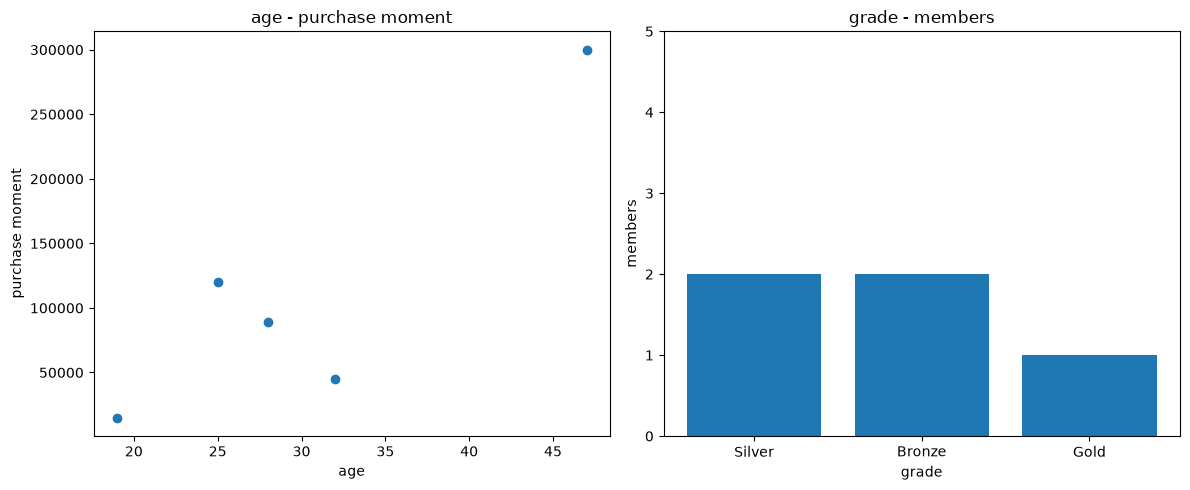

In [21]:
import matplotlib.pyplot as plt

plt.subplots(1,2, figsize=(12,5))

# 산점도 그래프
plt.subplot(1,2,1)
plt.scatter(df['나이'], df['구매금액'])
plt.title("age - purchase moment")
plt.xlabel("age")
plt.ylabel("purchase moment")

# 막대 그래프
x_values = df['등급'].unique()
y_values = df['등급'].value_counts()
plt.subplot(1,2,2)
plt.bar(x_values, y_values)
plt.title("grade - members")
plt.xlabel("grade")
plt.ylabel("members")
plt.ylim(0, 5)

plt.tight_layout()
plt.show()
